In [ ]:
# ============================================
# کد ۱: آموزش SVM + ذخیره باندل — دیتاست MH Text
# ============================================
%pip install pandas scikit-learn nltk matplotlib seaborn openpyxl shap lime -q

import os, re, time, pickle, warnings
import numpy as np
import pandas as pd
import nltk
from pathlib import Path
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report)
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

nltk.download('stopwords', quiet=True)

# ============================================
# ⚙️ CONFIG
# ============================================
CONFIG = {
    "name": "mh_text",
    "description": "Mental Health Text Classification (3 classes after removing Normal)",

    # 📁 مسیر پوشه
    "data_dir": "/content/drive/MyDrive/nusrat_data/data/dataset3",
    "train_file": "mental_health_unbalanced.csv",
    "test_file": "mental_health_combined_test.csv",

    # 📋 ستون‌ها
    "text_col": "text",
    "label_col": "status",

    # 🗑️ کلاس کنترل
    "control_class": "Normal",
}

print(f"📊 دیتاست: {CONFIG['name']}")
print(f"   {CONFIG['description']}")

# ============================================
# اتصال Drive
# ============================================
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

DATA_DIR = Path(CONFIG['data_dir'])
TRAIN_PATH = DATA_DIR / CONFIG['train_file']
TEST_PATH = DATA_DIR / CONFIG['test_file']

print(f"\n📁 Train: {TRAIN_PATH} (موجود: {TRAIN_PATH.exists()})")
print(f"📁 Test:  {TEST_PATH} (موجود: {TEST_PATH.exists()})")

# ============================================
# پوشه‌های خروجی
# ============================================
DRIVE_BASE = Path("/content/drive/MyDrive/nusrat_data")
DATASET_DIR = DRIVE_BASE / "models" / CONFIG['name']
DATASET_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = DRIVE_BASE / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BUNDLE_PATH = DATASET_DIR / "svm_bundle.pkl"
RESULTS_CSV = RESULTS_DIR / f"{CONFIG['name']}_svm_results.csv"

print(f"\n📁 باندل: {BUNDLE_PATH}")
print(f"📁 نتایج: {RESULTS_CSV}")

# ============================================
# بررسی اتمام قبلی
# ============================================
if BUNDLE_PATH.exists():
    print(f"\n✅ این دیتاست قبلاً پردازش شده است!")
    print(f"   برای اجرای مجدد، {BUNDLE_PATH} را حذف کنید.")
else:
    if not TRAIN_PATH.exists() or not TEST_PATH.exists():
        raise FileNotFoundError(f"❌ فایل‌های دیتاست پیدا نشدند.")

    print(f"\n🔨 شروع پردازش دیتاست...")

    # ============================================
    # 1. بارگذاری
    # ============================================
    df_train = pd.read_csv(str(TRAIN_PATH), encoding='latin-1')
    df_test = pd.read_csv(str(TEST_PATH), encoding='latin-1')

    print(f"\n✅ Train: {len(df_train)} | Test: {len(df_test)}")
    print(f"📌 ستون‌های Train: {df_train.columns.tolist()}")
    print(f"📌 ستون‌های Test:  {df_test.columns.tolist()}")

    # ============================================
    # 2. پیش‌پردازش
    # ============================================
    def preprocess(df):
        # حذف ستون index اگر وجود دارد
        if df.columns[0].startswith('Unnamed') or df.columns[0] == '':
            df = df.iloc[:, 1:]
        df = df.rename(columns={CONFIG['text_col']: 'text',
                                 CONFIG['label_col']: 'label'})
        df = df.dropna(subset=['text', 'label']).reset_index(drop=True)
        df['text'] = df['text'].astype(str).str.strip()
        df = df[df['text'].str.len() > 0].reset_index(drop=True)
        return df

    df_train = preprocess(df_train)
    df_test = preprocess(df_test)

    print(f"\n✅ بعد از پاکسازی:")
    print(f"   Train: {len(df_train)}")
    print(f"   Test:  {len(df_test)}")

    print(f"\n📊 توزیع کلاس‌ها در Train (قبل از فیلتر):")
    print(df_train['label'].value_counts())
    print(f"\n📊 توزیع کلاس‌ها در Test (قبل از فیلتر):")
    print(df_test['label'].value_counts())

    # ============================================
    # 3. حذف کلاس کنترل
    # ============================================
    if CONFIG['control_class'] is not None:
        before_train = len(df_train)
        before_test = len(df_test)
        df_train = df_train[df_train['label'] != CONFIG['control_class']].reset_index(drop=True)
        df_test = df_test[df_test['label'] != CONFIG['control_class']].reset_index(drop=True)
        print(f"\n🗑️ حذف کلاس '{CONFIG['control_class']}':")
        print(f"   Train: {before_train} → {len(df_train)}")
        print(f"   Test:  {before_test} → {len(df_test)}")

    # ============================================
    # 4. کدگذاری برچسب‌ها
    # ============================================
    label_encoder = LabelEncoder()
    df_train['label_encoded'] = label_encoder.fit_transform(df_train['label'])
    df_test['label_encoded'] = label_encoder.transform(df_test['label'])
    n_classes = len(label_encoder.classes_)

    print(f"\n📌 نگاشت برچسب‌ها ({n_classes} کلاس):")
    for i, cls in enumerate(label_encoder.classes_):
        cnt_train = (df_train['label_encoded'] == i).sum()
        cnt_test = (df_test['label_encoded'] == i).sum()
        print(f"   {i}: {cls} (Train: {cnt_train}, Test: {cnt_test})")

    # ============================================
    # 5. پاکسازی متن
    # ============================================
    stop_words = set(stopwords.words('english'))

    def clean_text(text):
        if not isinstance(text, str):
            return ""
        text = text.lower()
        text = re.sub(r'\d+', '', text)
        text = re.sub(r'[^\w\s]', '', text)
        text = ' '.join([w for w in text.split() if w not in stop_words])
        return text.strip()

    df_train['clean_text'] = df_train['text'].apply(clean_text)
    df_test['clean_text'] = df_test['text'].apply(clean_text)
    df_train = df_train[df_train['clean_text'].str.len() > 0].reset_index(drop=True)
    df_test = df_test[df_test['clean_text'].str.len() > 0].reset_index(drop=True)

    print(f"\n✅ بعد از پاکسازی متن - Train: {len(df_train)}, Test: {len(df_test)}")

    # ============================================
    # 6. TF-IDF
    # ============================================
    vectorizer = TfidfVectorizer(
        max_features=30000, ngram_range=(1, 2),
        min_df=2, sublinear_tf=True
    )
    X_train_tfidf = vectorizer.fit_transform(df_train['clean_text'].values)
    X_test_tfidf = vectorizer.transform(df_test['clean_text'].values)
    y_train = df_train['label_encoded'].values
    y_test = df_test['label_encoded'].values

    print(f"✅ ابعاد TF-IDF: Train={X_train_tfidf.shape}, Test={X_test_tfidf.shape}")

    # ============================================
    # 7. آموزش ۴ طبقه‌بند
    # ============================================
    classifiers = {
        'Logistic Regression': LogisticRegression(
            max_iter=2000, class_weight='balanced',
            random_state=42, multi_class='multinomial'
        ),
        'Linear SVM': LinearSVC(
            C=1.0, class_weight='balanced',
            random_state=42, max_iter=5000
        ),
        'Multinomial Naive Bayes': MultinomialNB(alpha=1.0),
        'Random Forest': RandomForestClassifier(
            n_estimators=300, class_weight='balanced',
            random_state=42, n_jobs=-1
        )
    }

    results = {}
    training_times = {}

    for name, clf in classifiers.items():
        print(f"\n{'='*60}\n🔄 {name}\n{'='*60}")

        start = time.time()
        clf.fit(X_train_tfidf, y_train)
        training_times[name] = time.time() - start

        y_pred = clf.predict(X_test_tfidf)

        acc = accuracy_score(y_test, y_pred)
        macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
        weighted_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

        results[name] = {
            'Accuracy': acc * 100,
            'Macro-F1': macro_f1 * 100,
            'Weighted-F1': weighted_f1 * 100,
            'y_pred': y_pred,
            'training_time': training_times[name],
        }
        print(f"   Accuracy: {acc*100:.2f}% | Macro-F1: {macro_f1*100:.2f}% | زمان: {training_times[name]:.2f}s")
        print(f"\n   Classification Report:")
        print(classification_report(y_test, y_pred,
                                     target_names=label_encoder.classes_,
                                     zero_division=0))

    # جدول خلاصه
    results_df = pd.DataFrame({
        name: {
            'Accuracy (%)': m['Accuracy'],
            'Macro F1 (%)': m['Macro-F1'],
            'Weighted F1 (%)': m['Weighted-F1'],
            'Training Time (s)': m['training_time'],
        }
        for name, m in results.items()
    }).T

    print("\n" + "="*80)
    print(f"📊 جدول نهایی — {CONFIG['name']}")
    print("="*80)
    print(results_df.round(2).to_string())

    # ============================================
    # 8. ذخیره باندل
    # ============================================
    bundle = {
        'config': CONFIG,
        'df_train': df_train,
        'df_test': df_test,
        'classifiers': classifiers,
        'vectorizer': vectorizer,
        'label_encoder': label_encoder,
        'results': results,
        'results_df': results_df,
        'training_times': training_times,
        'X_train': df_train['clean_text'].values,
        'X_test': df_test['clean_text'].values,
        'y_train': y_train,
        'y_test': y_test,
        'X_train_tfidf': X_train_tfidf,
        'X_test_tfidf': X_test_tfidf,
        'n_classes': n_classes,
        'class_names': list(label_encoder.classes_),
    }

    with open(BUNDLE_PATH, 'wb') as f:
        pickle.dump(bundle, f)

    bundle_size = os.path.getsize(BUNDLE_PATH) / 1024 / 1024
    print(f"\n✅ باندل ذخیره شد: {BUNDLE_PATH} ({bundle_size:.2f} MB)")

    results_df.round(4).to_csv(RESULTS_CSV)
    print(f"✅ نتایج ذخیره شد: {RESULTS_CSV}")

    # ============================================
    # 9. خلاصه
    # ============================================
    best = max(results, key=lambda x: results[x]['Macro-F1'])
    print(f"\n🏆 بهترین مدل: {best}")
    print(f"   Macro-F1:    {results[best]['Macro-F1']:.2f}%")
    print(f"   Weighted-F1: {results[best]['Weighted-F1']:.2f}%")
    print(f"   Accuracy:    {results[best]['Accuracy']:.2f}%")

📊 دیتاست: mh_text
   Mental Health Text Classification (3 classes after removing Normal)

📁 Train: /content/drive/MyDrive/nusrat_data/data/dataset3/mental_health_unbalanced.csv (موجود: True)
📁 Test:  /content/drive/MyDrive/nusrat_data/data/dataset3/mental_health_combined_test.csv (موجود: True)

📁 باندل: /content/drive/MyDrive/nusrat_data/models/mh_text/svm_bundle.pkl
📁 نتایج: /content/drive/MyDrive/nusrat_data/results/mh_text_svm_results.csv

🔨 شروع پردازش دیتاست...

✅ Train: 49612 | Test: 992
📌 ستون‌های Train: ['Unique_ID', 'text', 'status']
📌 ستون‌های Test:  ['text', 'status']

✅ بعد از پاکسازی:
   Train: 49612
   Test:  992

📊 توزیع کلاس‌ها در Train (قبل از فیلتر):
label
Normal        18391
Depression    14506
Suicidal      11212
Anxiety        5503
Name: count, dtype: int64

📊 توزیع کلاس‌ها در Test (قبل از فیلتر):
label
Anxiety       248
Depression    248
Normal        248
Suicidal      248
Name: count, dtype: int64

🗑️ حذف کلاس 'Normal':
   Train: 49612 → 31221
   Test:  992 → 744

In [ ]:
# ============================================
# کد ۲: XAI برای SVM — MH Text (3 کلاس)
# ============================================
%pip install shap lime -q

import os, re, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import nltk
from nltk.corpus import stopwords

warnings.filterwarnings('ignore')

from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# ⚠️ مسیر صحیح (بر اساس خروجی شما)
DRIVE_BASE = Path("/content/drive/MyDrive/nusrat_data")
BUNDLE_PATH = DRIVE_BASE / "models" / "mh_text" / "svm_bundle.pkl"
XAI_DIR = DRIVE_BASE / "plots" / "xai_svm_mh_text"
SHAP_DIR = XAI_DIR / "shap"
LIME_DIR = XAI_DIR / "lime"
FEAT_DIR = XAI_DIR / "features"
for d in [SHAP_DIR, LIME_DIR, FEAT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"📁 باندل: {BUNDLE_PATH}")
print(f"📁 خروجی: {XAI_DIR}")
print(f"   موجود: {BUNDLE_PATH.exists()}")

if not BUNDLE_PATH.exists():
    raise FileNotFoundError(f"❌ باندل پیدا نشد: {BUNDLE_PATH}")

bundle_size = os.path.getsize(BUNDLE_PATH) / 1024 / 1024
print(f"📊 حجم باندل: {bundle_size:.1f} MB")
print("⏳ بارگذاری...")

# ============================================
# تابع پاکسازی متن
# ============================================
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = ' '.join([w for w in text.split() if w not in stop_words])
    return text.strip()

# ============================================
# بارگذاری باندل
# ============================================
with open(BUNDLE_PATH, 'rb') as f:
    bundle = pickle.load(f)

df_train = bundle['df_train']
df_test = bundle['df_test']
classifiers = bundle['classifiers']
vectorizer = bundle['vectorizer']
label_encoder = bundle['label_encoder']
results_df = bundle['results_df']
y_train = bundle['y_train']
y_test = bundle['y_test']
X_train_tfidf = bundle['X_train_tfidf']
X_test_tfidf = bundle['X_test_tfidf']
X_test = bundle['X_test']
n_classes = bundle['n_classes']
class_names = bundle['class_names']

print(f"✅ باندل بارگذاری شد.")
print(f"   تعداد کلاس‌ها: {n_classes}")
print(f"   کلاس‌ها: {class_names}")
print(f"   Test: {len(y_test)} نمونه")


# ============================================
# بخش ۱: SHAP (LinearExplainer)
# ============================================
print("\n" + "=" * 70)
print("🔍 بخش ۱: SHAP")
print("=" * 70)

import shap

svm_model = classifiers['Linear SVM']

explainer_shap = shap.LinearExplainer(
    svm_model, X_train_tfidf,
    feature_perturbation="interventional"
)
print("✅ LinearExplainer ساخته شد.")

np.random.seed(42)
sample_size = min(100, X_test_tfidf.shape[0])
sample_idx = np.random.choice(X_test_tfidf.shape[0], sample_size, replace=False)
X_sample = X_test_tfidf[sample_idx]

print(f"⏳ محاسبه SHAP روی {sample_size} نمونه...")
shap_values = explainer_shap(X_sample)
sv = shap_values.values
print(f"✅ SHAP محاسبه شد. Shape: {sv.shape}")

feature_names = vectorizer.get_feature_names_out()

# SHAP summary per class
for cls_id, cls_name in enumerate(class_names):
    plt.figure(figsize=(10, 6))
    mean_abs_shap = np.abs(sv[:, :, cls_id]).mean(axis=0)
    top_idx = np.argsort(mean_abs_shap)[-20:][::-1]
    top_features = [feature_names[i] for i in top_idx]
    top_values = mean_abs_shap[top_idx]

    plt.barh(list(reversed(top_features)), list(reversed(top_values)),
             color='#2c5f8a', edgecolor='black')
    plt.title(f"Top 20 SHAP Features — {cls_name}", fontsize=13, fontweight='bold')
    plt.xlabel("Mean |SHAP value|", fontsize=11)
    plt.tight_layout()
    plt.savefig(str(SHAP_DIR / f"shap_summary_{cls_name}.png"),
                dpi=200, bbox_inches='tight')
    plt.close()
    print(f"   ✅ SHAP summary for {cls_name}")

# SHAP global
plt.figure(figsize=(10, 8))
global_imp = np.abs(sv).mean(axis=(0, 2))
top_idx = np.argsort(global_imp)[-20:][::-1]
top_features = [feature_names[i] for i in top_idx]
top_values = global_imp[top_idx]

plt.barh(list(reversed(top_features)), list(reversed(top_values)),
         color='#55A868', edgecolor='black')
plt.title("Top 20 Global SHAP Features (All Classes)", fontsize=13, fontweight='bold')
plt.xlabel("Mean |SHAP value|", fontsize=11)
plt.tight_layout()
plt.savefig(str(SHAP_DIR / "shap_global_summary.png"),
            dpi=200, bbox_inches='tight')
plt.close()
print("   ✅ SHAP global summary")


# ============================================
# بخش ۲: LIME
# ============================================
print("\n" + "=" * 70)
print("🔍 بخش ۲: LIME")
print("=" * 70)

from lime.lime_text import LimeTextExplainer

def predict_proba_svm(texts):
    cleaned = [clean_text(t) for t in texts]
    X = vectorizer.transform(cleaned)
    decision = svm_model.decision_function(X)
    exp_d = np.exp(decision - decision.max(axis=1, keepdims=True))
    return exp_d / exp_d.sum(axis=1, keepdims=True)

lime_explainer = LimeTextExplainer(class_names=class_names)

# انتخاب نمونه‌ها (۲ از هر کلاس = ۶ نمونه)
test_df = pd.DataFrame({'text': X_test, 'labels': y_test})

sample_texts, sample_true_labels, sample_true_ids = [], [], []
for cls_id, cls_name in enumerate(class_names):
    cls_examples = test_df[test_df['labels'] == cls_id]['text'].head(2).tolist()
    sample_texts.extend(cls_examples)
    sample_true_labels.extend([cls_name] * len(cls_examples))
    sample_true_ids.extend([cls_id] * len(cls_examples))

print(f"⏳ اجرای LIME روی {len(sample_texts)} نمونه...")

lime_results_csv = []

for idx, (text, true_label, true_id) in enumerate(zip(sample_texts, sample_true_labels, sample_true_ids)):
    try:
        exp = lime_explainer.explain_instance(
            text, predict_proba_svm,
            num_features=10, num_samples=500,
            labels=[true_id]
        )

        save_html = LIME_DIR / f"lime_example_{idx}_{true_label}.html"
        exp.save_to_file(str(save_html))

        for word, weight in exp.as_list(label=true_id):
            lime_results_csv.append({
                'sample_id': idx,
                'true_label': true_label,
                'word': word,
                'weight': weight,
            })

        print(f"   ✅ [{idx+1}/{len(sample_texts)}] {true_label}")
    except Exception as e:
        print(f"   ⚠️ خطا در نمونه {idx}: {e}")

if lime_results_csv:
    lime_df = pd.DataFrame(lime_results_csv)
    lime_df.to_csv(str(LIME_DIR / "lime_results.csv"), index=False)
    print(f"\n✅ LIME CSV ذخیره شد.")

    word_imp = lime_df.groupby('word')['weight'].apply(lambda x: np.abs(x).mean())
    top20 = word_imp.sort_values(ascending=False).head(20)

    plt.figure(figsize=(10, 7))
    plt.barh(list(reversed(top20.index)), list(reversed(top20.values)),
             color='#C44E52', edgecolor='black')
    plt.title("Top 20 LIME Words (Mean |Weight|)", fontsize=13, fontweight='bold')
    plt.xlabel("Mean |Weight|", fontsize=11)
    plt.tight_layout()
    plt.savefig(str(LIME_DIR / "lime_summary.png"), dpi=200, bbox_inches='tight')
    plt.close()
    print(f"✅ نمودار LIME summary ذخیره شد.")


# ============================================
# بخش ۳: Feature Coefficients
# ============================================
print("\n" + "=" * 70)
print("🔍 بخش ۳: Feature Coefficients")
print("=" * 70)

feature_names = vectorizer.get_feature_names_out()
coef_matrix = svm_model.coef_
print(f"   Shape: {coef_matrix.shape}")

# Heatmap
mean_abs_coef = np.abs(coef_matrix).mean(axis=0)
top30_idx = np.argsort(mean_abs_coef)[-30:][::-1]
top30_features = [feature_names[i] for i in top30_idx]
top30_coef = coef_matrix[:, top30_idx].T

fig, ax = plt.subplots(figsize=(8, 12))
sns.heatmap(top30_coef, annot=False, cmap='RdBu_r',
            xticklabels=class_names, yticklabels=top30_features,
            center=0, cbar_kws={'label': 'Coefficient'}, ax=ax)
ax.set_title("Top 30 Features × Classes — SVM Coefficients",
             fontsize=13, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(FEAT_DIR / "coefficient_heatmap.png"), dpi=200, bbox_inches='tight')
plt.close()
print("   ✅ Heatmap ذخیره شد.")

# Bar charts per class
n_cols = 3
n_rows = (n_classes + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, cls_name in enumerate(class_names):
    top_idx = np.argsort(coef_matrix[i])[-15:][::-1]
    top_features = [feature_names[j] for j in top_idx]
    top_scores = [coef_matrix[i][j] for j in top_idx]

    axes[i].barh(list(reversed(top_features)), list(reversed(top_scores)),
                 color='#2c5f8a', edgecolor='black')
    axes[i].set_title(f"Top Features — {cls_name}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Coefficient", fontsize=10)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle("Top 15 Features per Class — SVM Coefficients",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(FEAT_DIR / "coefficients_per_class.png"), dpi=200, bbox_inches='tight')
plt.close()
print("   ✅ Per-class bar charts ذخیره شد.")

# CSV
coef_df = pd.DataFrame(coef_matrix.T, index=feature_names, columns=class_names)
top100_idx = np.argsort(mean_abs_coef)[-100:][::-1]
coef_df.iloc[top100_idx].to_csv(str(FEAT_DIR / "top100_coefficients.csv"))
print("   ✅ CSV ضرایب ذخیره شد.")


# ============================================
# گزارش نهایی
# ============================================
print("\n" + "=" * 80)
print("✅ XAI برای SVM (MH Text) کامل شد!")
print("=" * 80)

for folder, label in [(SHAP_DIR, 'SHAP'), (LIME_DIR, 'LIME'), (FEAT_DIR, 'Features')]:
    files = sorted(os.listdir(folder))
    print(f"\n   {label} ({len(files)} فایل):")
    for f in files:
        size = os.path.getsize(folder / f) / 1024
        print(f"      ✅ {f} ({size:.1f} KB)")

print(f"\n   SVM Macro-F1: {results_df.loc['Linear SVM', 'Macro F1 (%)']:.2f}%")

📁 باندل: /content/drive/MyDrive/nusrat_data/models/mh_text/svm_bundle.pkl
📁 خروجی: /content/drive/MyDrive/nusrat_data/plots/xai_svm_mh_text
   موجود: True
📊 حجم باندل: 602.3 MB
⏳ بارگذاری...
✅ باندل بارگذاری شد.
   تعداد کلاس‌ها: 3
   کلاس‌ها: ['Anxiety', 'Depression', 'Suicidal']
   Test: 744 نمونه

🔍 بخش ۱: SHAP


✅ LinearExplainer ساخته شد.
⏳ محاسبه SHAP روی 100 نمونه...
✅ SHAP محاسبه شد. Shape: (100, 30000, 3)
   ✅ SHAP summary for Anxiety
   ✅ SHAP summary for Depression
   ✅ SHAP summary for Suicidal
   ✅ SHAP global summary

🔍 بخش ۲: LIME
⏳ اجرای LIME روی 6 نمونه...
   ✅ [1/6] Anxiety
   ✅ [2/6] Anxiety
   ✅ [3/6] Depression
   ✅ [4/6] Depression
   ✅ [5/6] Suicidal
   ✅ [6/6] Suicidal

✅ LIME CSV ذخیره شد.
✅ نمودار LIME summary ذخیره شد.

🔍 بخش ۳: Feature Coefficients
   Shape: (3, 30000)
   ✅ Heatmap ذخیره شد.
   ✅ Per-class bar charts ذخیره شد.
   ✅ CSV ضرایب ذخیره شد.

✅ XAI برای SVM (MH Text) کامل شد!

   SHAP (4 فایل):
      ✅ shap_global_summary.png (81.3 KB)
      ✅ shap_summary_Anxiety.png (77.8 KB)
      ✅ shap_summary_Depression.png (73.2 KB)
      ✅ shap_summary_Suicidal.png (72.7 KB)

   LIME (8 فایل):
      ✅ lime_example_0_Anxiety.html (1203.6 KB)
      ✅ lime_example_1_Anxiety.html (1203.9 KB)
      ✅ lime_example_2_Depression.html (1203.5 KB)
      ✅ lime_example_3_Depressi

In [ ]:
# ============================================
# کد ۳-الف: نصب فونت فارسی Vazirmatn (پایدار)
# ============================================
import warnings, os, subprocess
warnings.filterwarnings('ignore')

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# --- تلاش ۱: دانلود از jsdelivr CDN (پایدارترین) ---
FONT_PATH = '/tmp/Vazirmatn-Regular.ttf'

if not os.path.exists(FONT_PATH) or os.path.getsize(FONT_PATH) < 10000:
    print("📥 دانلود فونت از jsdelivr CDN...")
    subprocess.run(
        'wget -q "https://cdn.jsdelivr.net/gh/rastikerdar/vazirmatn@v33.003/fonts/ttf/Vazirmatn-Regular.ttf" '
        f'-O {FONT_PATH}',
        shell=True, capture_output=True
    )

# --- ثبت فونت در matplotlib ---
if os.path.exists(FONT_PATH) and os.path.getsize(FONT_PATH) > 10000:
    fm.fontManager.addfont(FONT_PATH)
    chosen_font = fm.FontProperties(fname=FONT_PATH).get_name()
    plt.rcParams['font.family'] = chosen_font
    print(f"✅ فونت ثبت شد: '{chosen_font}'")
    print(f"   مسیر: {FONT_PATH}")
    print(f"   حجم: {os.path.getsize(FONT_PATH) / 1024:.1f} KB")
else:
    print("❌ فونت نصب نشد — متن‌های فارسی مربع خواهند بود")

plt.rcParams['axes.unicode_minus'] = False

# --- ایمپورت‌های فارسی‌سازی ---
!pip install arabic-reshaper python-bidi -q
import arabic_reshaper
from bidi.algorithm import get_display

def fa(text):
    """تبدیل متن فارسی برای نمایش صحیح در matplotlib"""
    try:
        return get_display(arabic_reshaper.reshape(str(text)))
    except Exception:
        return str(text)

# --- تست فونت ---
fig, ax = plt.subplots(figsize=(6, 1))
ax.text(0.5, 0.5, fa('تست نمایش متن فارسی'),
        fontsize=18, ha='center', va='center')
ax.axis('off')
plt.tight_layout()
plt.savefig('/tmp/font_test.png', dpi=80, bbox_inches='tight')
plt.close()
print("🔍 فایل تست: /tmp/font_test.png")
print("   (اگر متن فارسی درست نمایش داده شد، ادامه دهید)")

📥 دانلود فونت از jsdelivr CDN...
✅ فونت ثبت شد: 'Vazirmatn'
   مسیر: /tmp/Vazirmatn-Regular.ttf
   حجم: 119.9 KB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 10.3 MB/s eta 0:00:00
🔍 فایل تست: /tmp/font_test.png
   (اگر متن فارسی درست نمایش داده شد، ادامه دهید)


📁 باندل: /content/drive/MyDrive/nusrat_data/models/mh_text/svm_bundle.pkl
📁 خروجی: /content/drive/MyDrive/nusrat_data/plots/mh_text/svm
   موجود: True

⏳ بارگذاری باندل (۶۰۲ MB)...
✅ باندل بارگذاری شد.
   تعداد کلاس‌ها: 3
   کلاس‌ها: ['Anxiety', 'Depression', 'Suicidal']
   Test: 744 نمونه

📊 شروع رسم ۱۵ نمودار برای 3 کلاس...
📊 [1/15] توزیع کلاس‌ها...


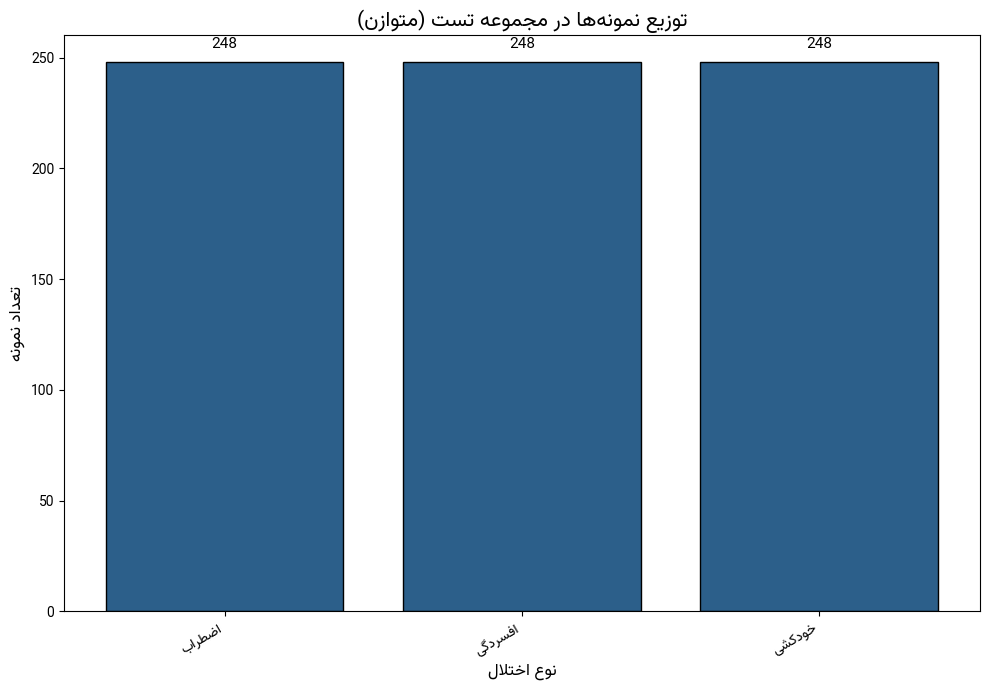

📊 [2/15] توزیع طول متن...


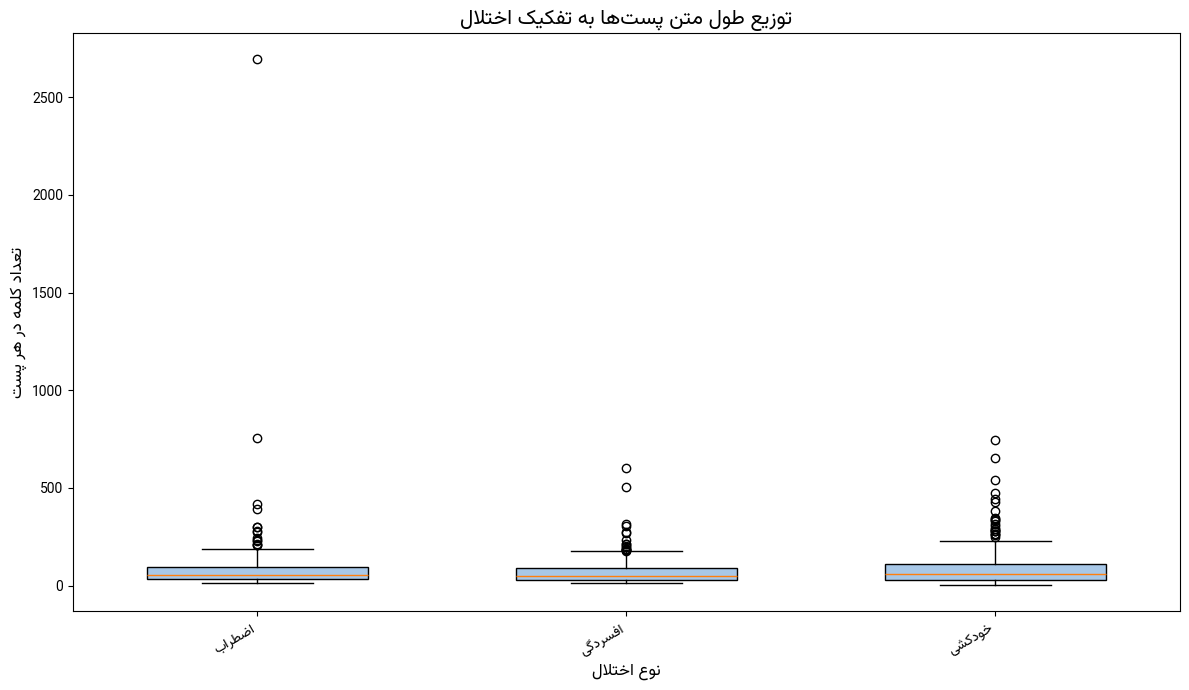

📊 [3/15] توزیع کلی طول پست‌ها...


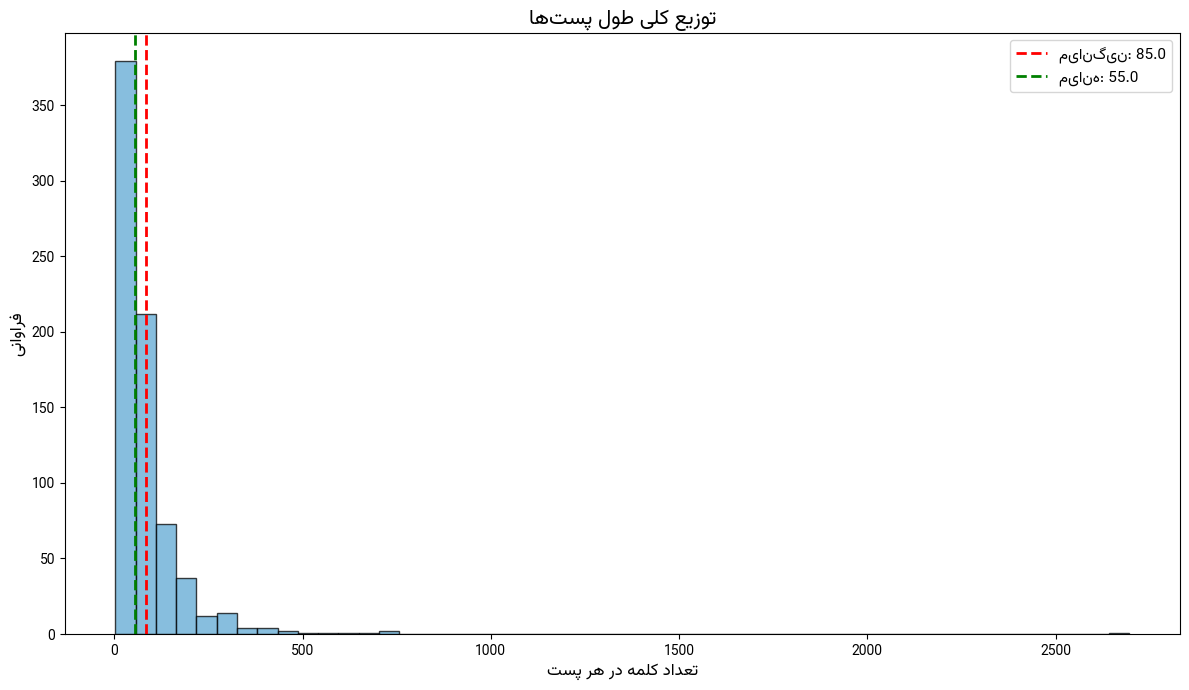

📊 [4/15] پرتکرارترین n-gram ها...


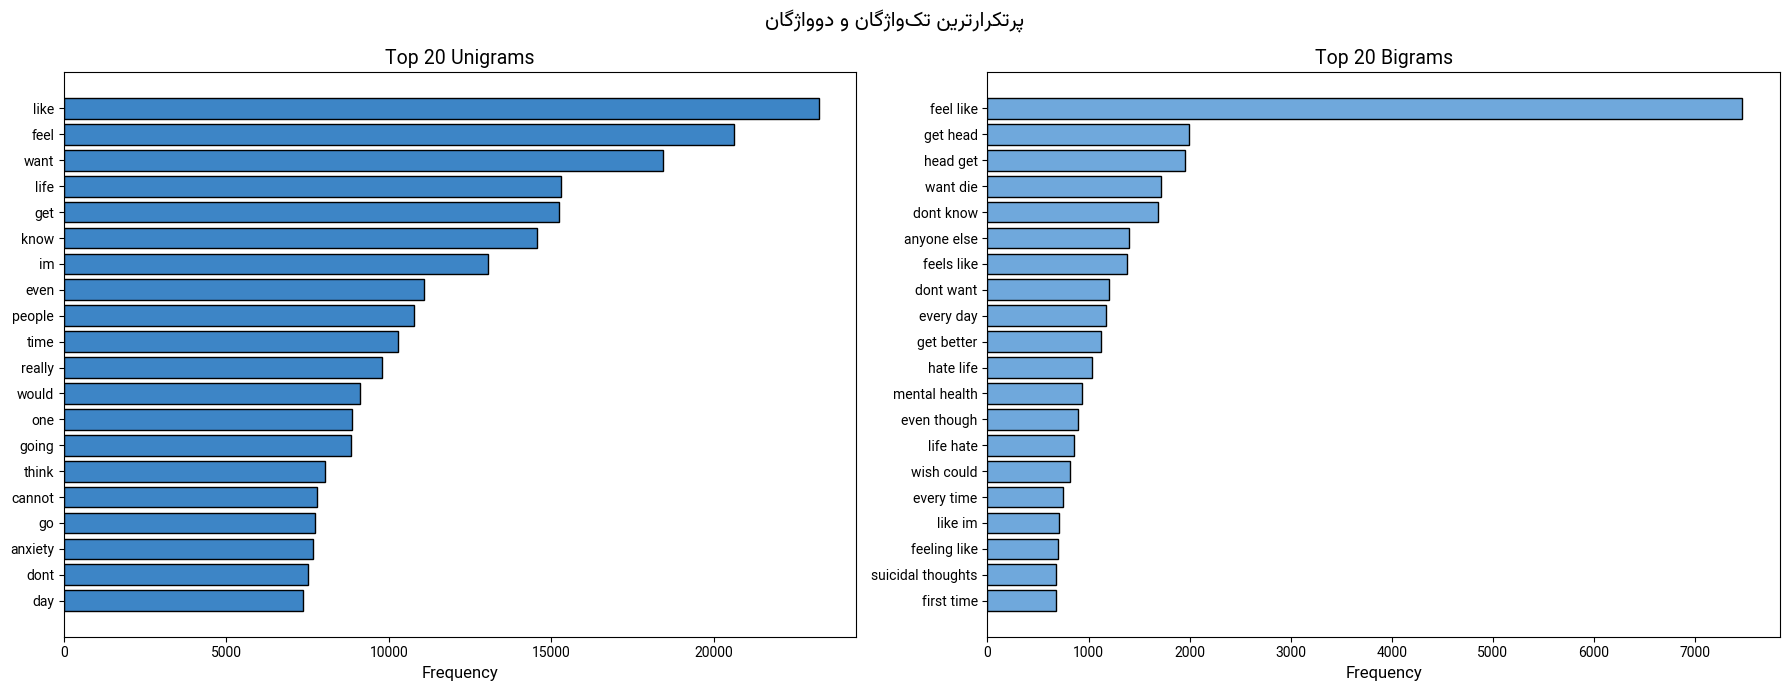

📊 [5/15] ابر واژگان...


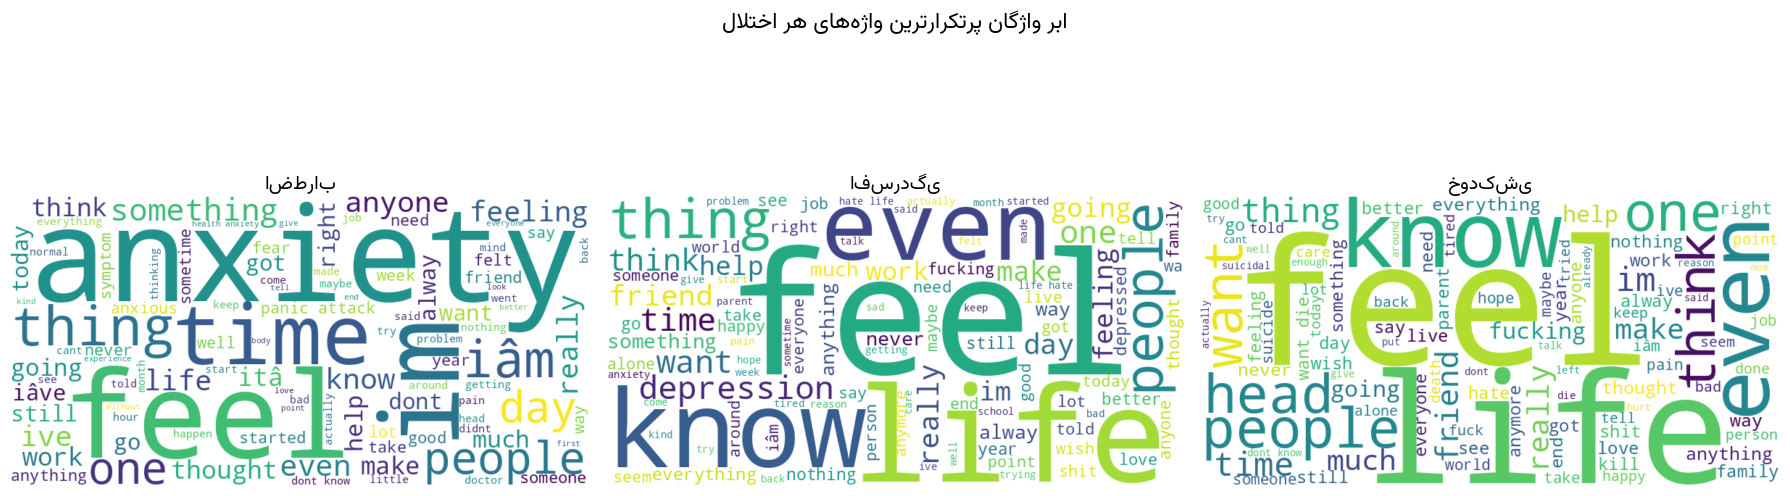

📊 [6/15] مقایسه عملکرد مدل‌ها...


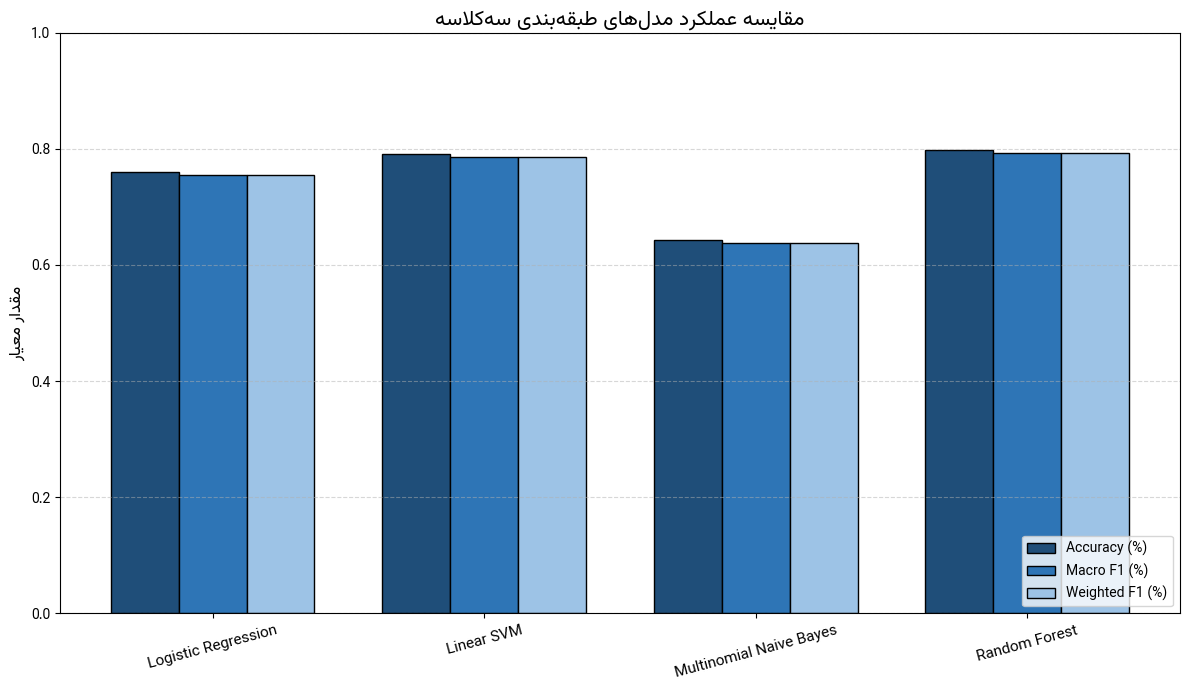

📊 [7/15] پایداری با ۵-fold CV (چند دقیقه)...
   Logistic Regression: 0.7594 ± 0.0062
   Linear SVM: 0.7464 ± 0.0033
   Multinomial Naive Bayes: 0.6906 ± 0.0091
   Random Forest: 0.7103 ± 0.0118


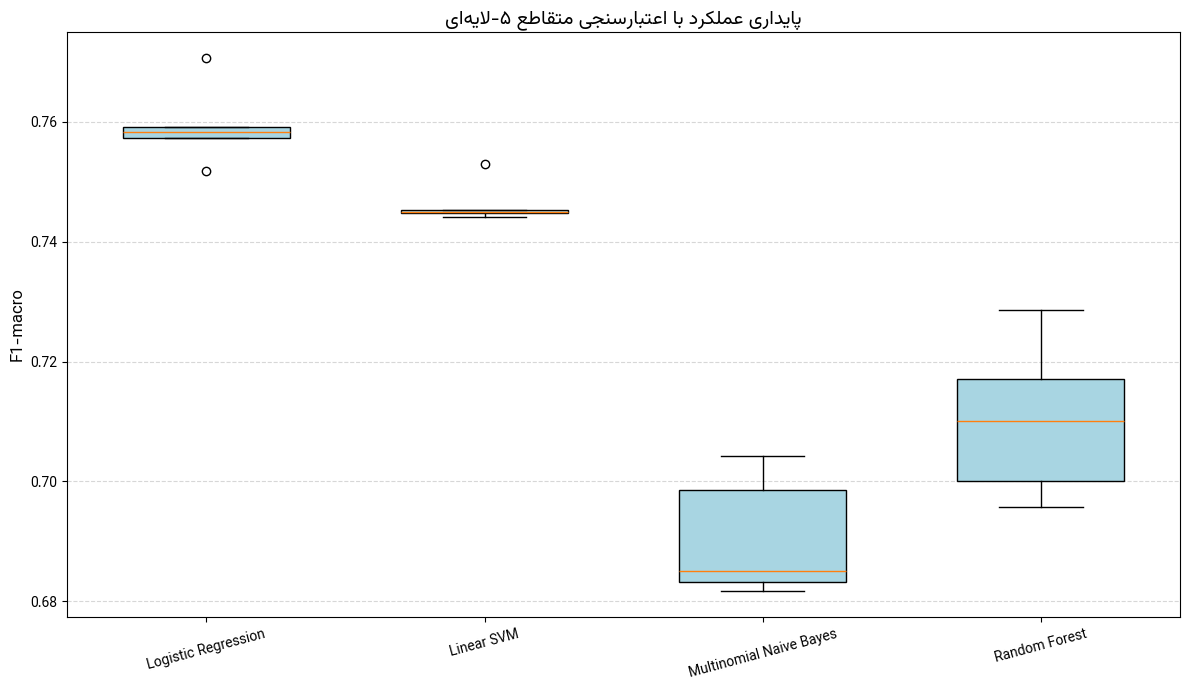

📊 [8/15] زمان آموزش...


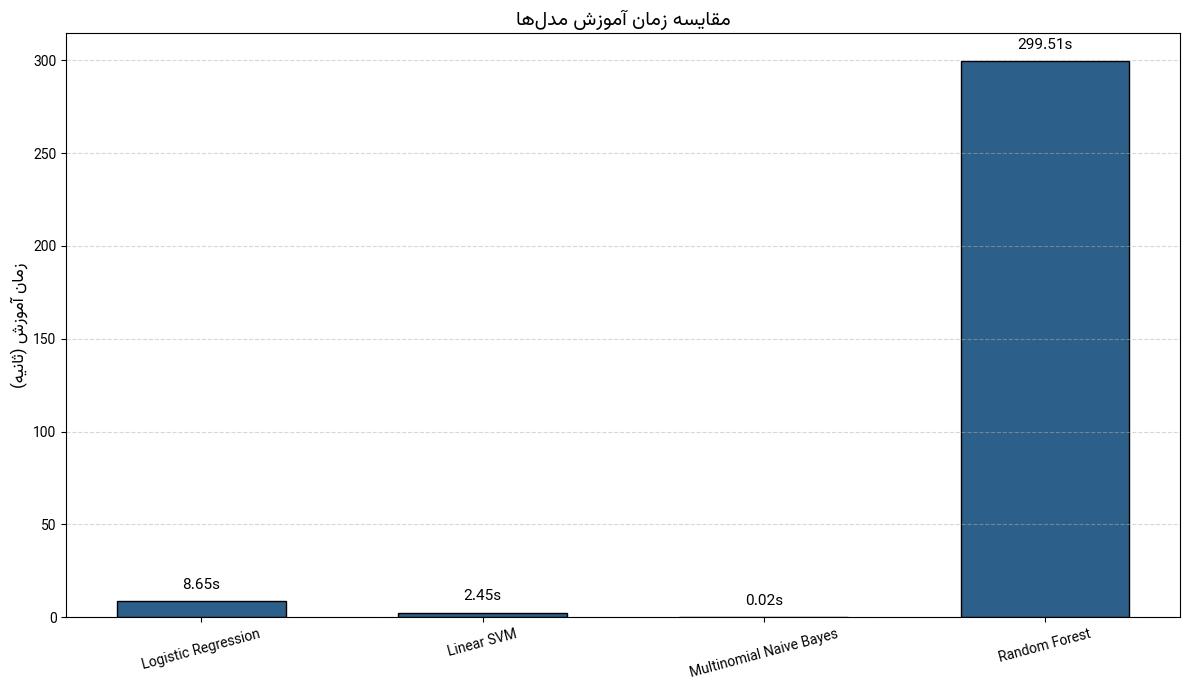

📊 [9/15] ماتریس درهم‌ریختگی SVM...


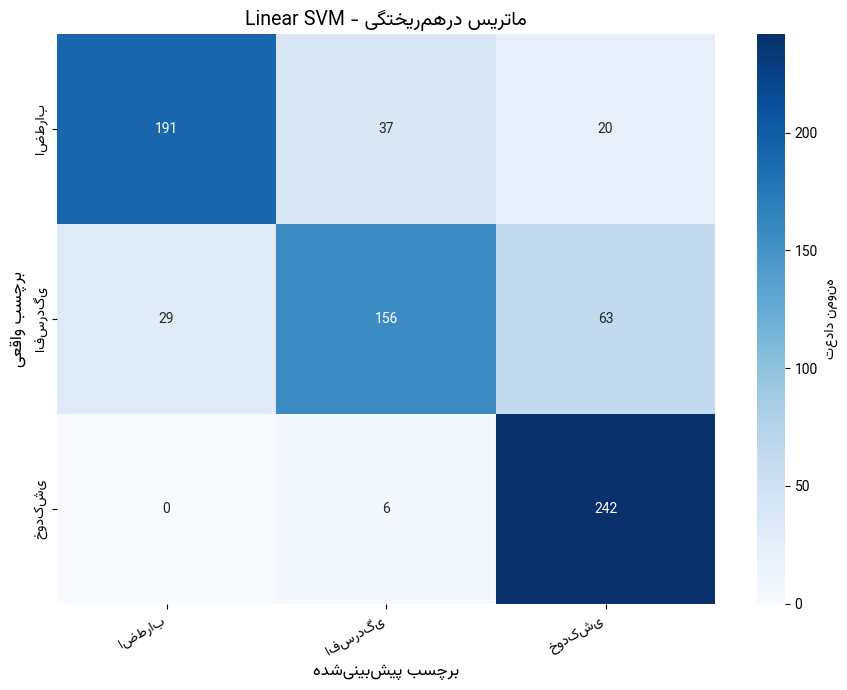

📊 [10/15] ماتریس نرمال‌شده SVM...


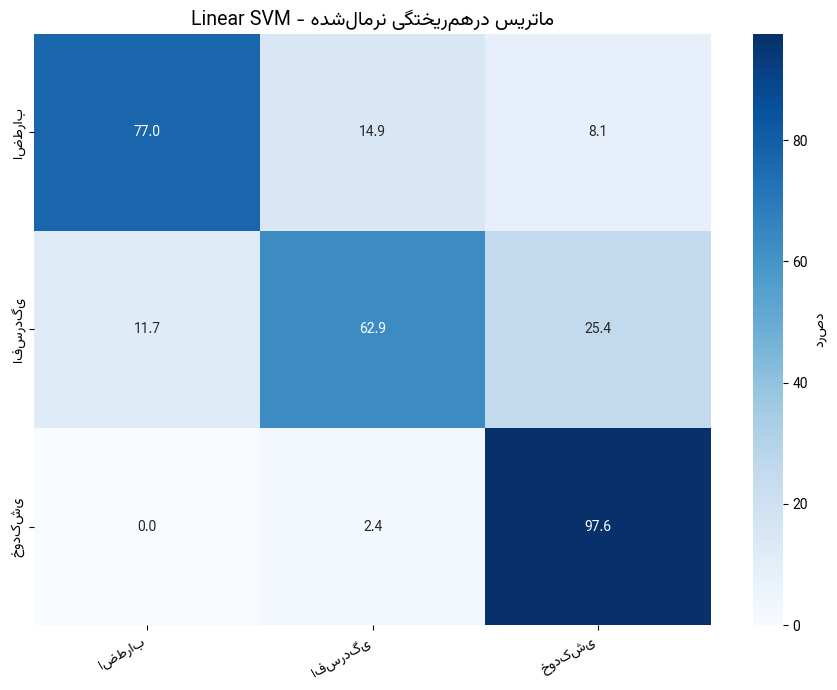

📊 [11/15] معیارها به تفکیک کلاس...


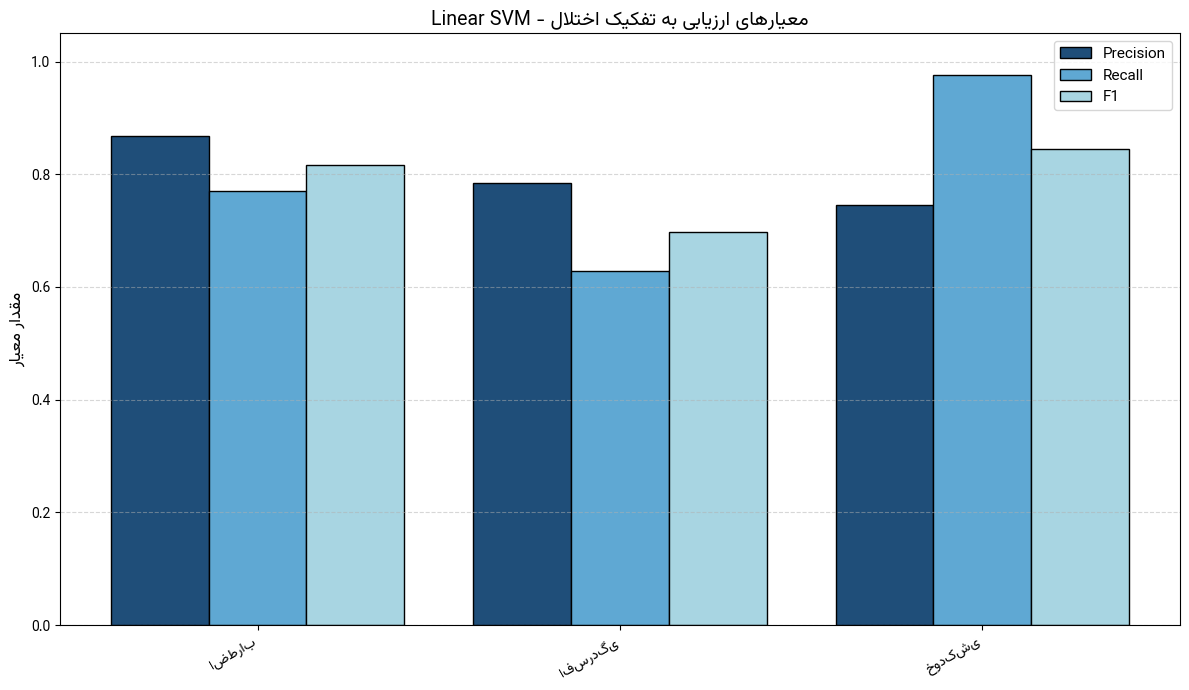

📊 [12/15] ROC...


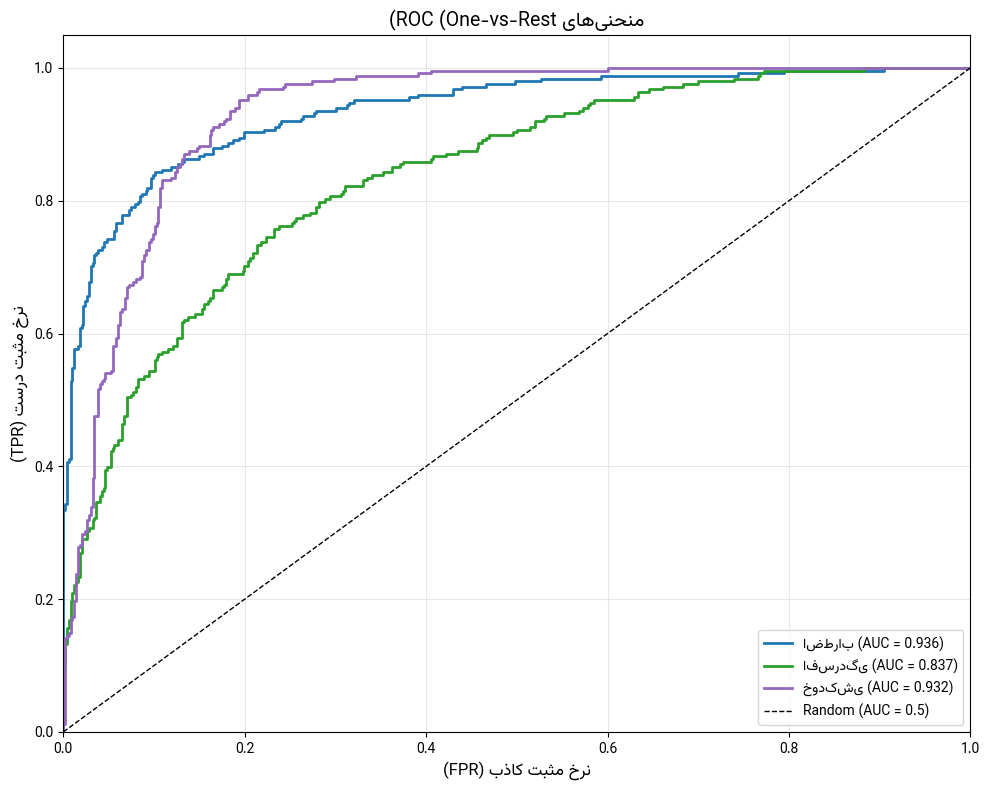

📊 [13/15] Precision-Recall...


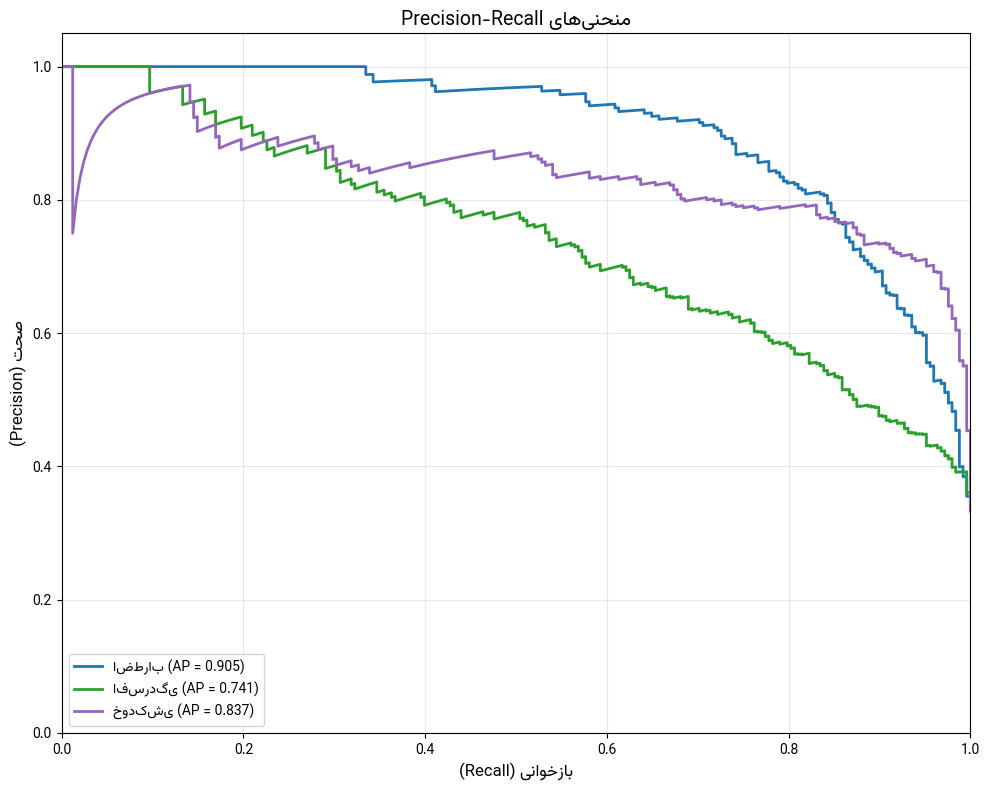

📊 [14/15] SVD...


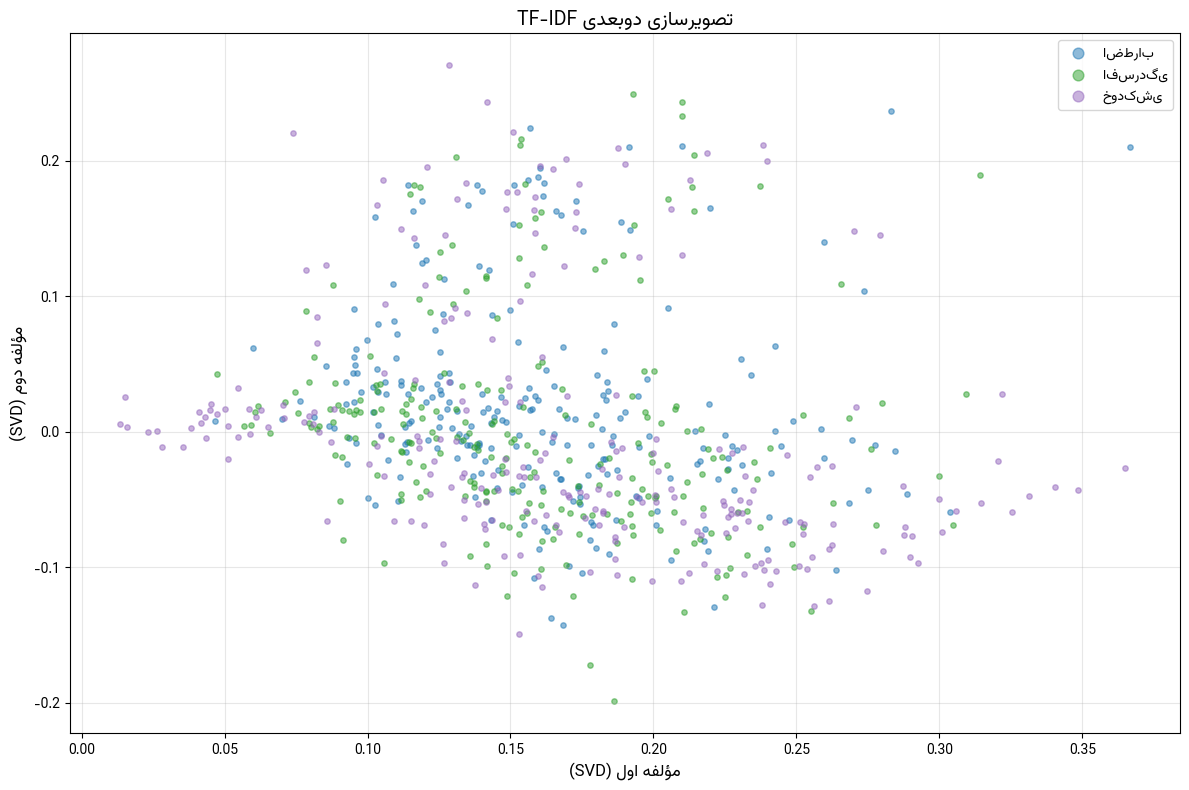

📊 [15/15] مهم‌ترین واژگان...


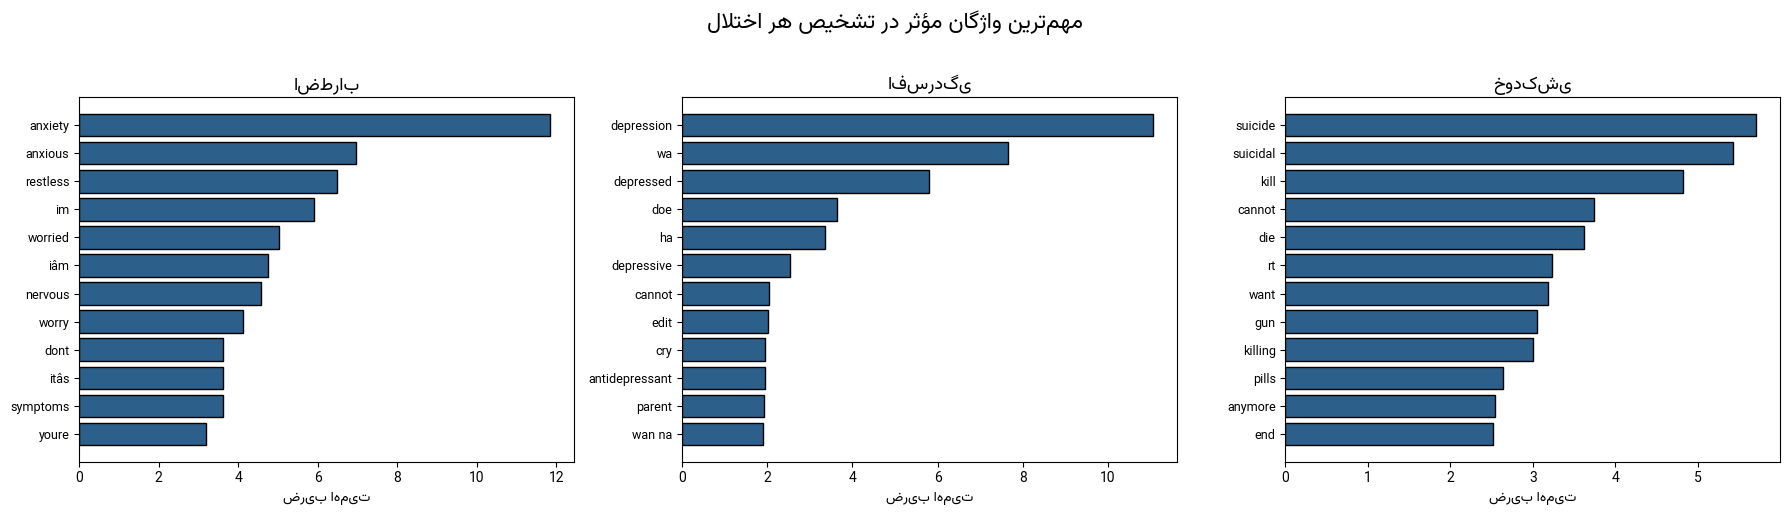


✅ همه‌ی ۱۵ نمودار با موفقیت ذخیره شدند!
📁 مسیر: /content/drive/MyDrive/nusrat_data/plots/mh_text/svm

📋 لیست فایل‌ها:
   ✅ fig_10_4_confusion_matrix_normalized_SVM.png (128.1 KB)
   ✅ fig_11_4_per_subtype_metrics_SVM.png (124.0 KB)
   ✅ fig_12_4_roc_curves.png (231.5 KB)
   ✅ fig_13_4_precision_recall_curves.png (220.3 KB)
   ✅ fig_14_4_tfidf_2d_visualization.png (536.6 KB)
   ✅ fig_15_4_top_features_per_class.png (195.4 KB)
   ✅ fig_1_4_class_distribution.png (102.9 KB)
   ✅ fig_2_4_length_by_subtype.png (138.8 KB)
   ✅ fig_3_4_length_histogram.png (113.9 KB)
   ✅ fig_4_4_ngrams.png (236.6 KB)
   ✅ fig_5_4_wordclouds.png (2253.4 KB)
   ✅ fig_6_4_classifier_comparison.png (190.1 KB)
   ✅ fig_7_4_cv_stability.png (157.4 KB)
   ✅ fig_8_4_training_time.png (172.8 KB)
   ✅ fig_9_4_confusion_matrix_SVM.png (145.2 KB)

🏆 خلاصه Linear SVM:
   Macro-F1:    78.63%
   Weighted-F1: 78.63%
   Accuracy:    79.17%


In [ ]:
# ============================================
# کد ۳-ب: رسم ۱۵ نمودار SVM — MH Text (۳ کلاس)
# ============================================
import os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
from wordcloud import WordCloud
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_recall_fscore_support
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings('ignore')

from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# ============================================
# مسیرها (⚠️ مطابق با خروجی شما)
# ============================================
DRIVE_BASE = Path("/content/drive/MyDrive/nusrat_data")
BUNDLE_PATH = DRIVE_BASE / "models" / "mh_text" / "svm_bundle.pkl"
OUTPUT_DIR = DRIVE_BASE / "plots" / "mh_text" / "svm"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"📁 باندل: {BUNDLE_PATH}")
print(f"📁 خروجی: {OUTPUT_DIR}")
print(f"   موجود: {BUNDLE_PATH.exists()}")

# ============================================
# بارگذاری باندل
# ============================================
print("\n⏳ بارگذاری باندل (۶۰۲ MB)...")
with open(BUNDLE_PATH, 'rb') as f:
    bundle = pickle.load(f)

df_train = bundle['df_train']
df_test = bundle['df_test']
classifiers = bundle['classifiers']
vectorizer = bundle['vectorizer']
label_encoder = bundle['label_encoder']
results = bundle['results']
results_df = bundle['results_df']
training_times = bundle['training_times']
X_train_tfidf = bundle['X_train_tfidf']
X_test_tfidf = bundle['X_test_tfidf']
y_train = bundle['y_train']
y_test = bundle['y_test']
n_classes = bundle['n_classes']
class_names = bundle['class_names']

print(f"✅ باندل بارگذاری شد.")
print(f"   تعداد کلاس‌ها: {n_classes}")
print(f"   کلاس‌ها: {class_names}")
print(f"   Test: {len(y_test)} نمونه")

# ============================================
# نام‌های فارسی ۳ کلاس
# ============================================
FA_LABELS = {
    'Suicidal': 'خودکشی',
    'Depression': 'افسردگی',
    'Anxiety': 'اضطراب',
}

colors_roc = ['#1f77b4', '#2ca02c', '#9467bd'][:n_classes]

print(f"\n📊 شروع رسم ۱۵ نمودار برای {n_classes} کلاس...")
print("=" * 70)


# ============================================
# نمودار ۱-۴: توزیع کلاس‌ها
# ============================================
print("📊 [1/15] توزیع کلاس‌ها...")
fig, ax = plt.subplots(figsize=(10, 7))
class_counts = df_test['label'].value_counts()
fa_names = [fa(FA_LABELS.get(name, name)) for name in class_counts.index]

bars = ax.bar(fa_names, class_counts.values, color='#2c5f8a', edgecolor='black')
for bar, count in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            f'{count:,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title(fa('توزیع نمونه‌ها در مجموعه تست (متوازن)'),
             fontsize=15, fontweight='bold')
ax.set_xlabel(fa('نوع اختلال'), fontsize=12)
ax.set_ylabel(fa('تعداد نمونه'), fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_1_4_class_distribution.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۲-۴: توزیع طول متن (Boxplot)
# ============================================
print("📊 [2/15] توزیع طول متن...")
df_test['word_count'] = df_test['clean_text'].apply(lambda x: len(x.split()))

fig, ax = plt.subplots(figsize=(12, 7))
data_by_class = [df_test[df_test['label'] == cls]['word_count'].values
                  for cls in class_counts.index]
bp = ax.boxplot(data_by_class,
                labels=[fa(FA_LABELS.get(c, c)) for c in class_counts.index],
                patch_artist=True, widths=0.6)
for patch in bp['boxes']:
    patch.set_facecolor('#a8c8e8')
    patch.set_edgecolor('black')

ax.set_title(fa('توزیع طول متن پست‌ها به تفکیک اختلال'),
             fontsize=15, fontweight='bold')
ax.set_xlabel(fa('نوع اختلال'), fontsize=12)
ax.set_ylabel(fa('تعداد کلمه در هر پست'), fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_2_4_length_by_subtype.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۳-۴: توزیع کلی طول پست‌ها
# ============================================
print("📊 [3/15] توزیع کلی طول پست‌ها...")
fig, ax = plt.subplots(figsize=(12, 7))
ax.hist(df_test['word_count'], bins=50, color='#5fa8d3',
        edgecolor='black', alpha=0.75)
ax.axvline(df_test['word_count'].mean(), color='red',
           linestyle='--', linewidth=2,
           label=f"میانگین: {df_test['word_count'].mean():.1f}")
ax.axvline(df_test['word_count'].median(), color='green',
           linestyle='--', linewidth=2,
           label=f"میانه: {df_test['word_count'].median():.1f}")

ax.set_title(fa('توزیع کلی طول پست‌ها'), fontsize=15, fontweight='bold')
ax.set_xlabel(fa('تعداد کلمه در هر پست'), fontsize=12)
ax.set_ylabel(fa('فراوانی'), fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_3_4_length_histogram.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۴-۴: پرتکرارترین n-gram ها
# ============================================
print("📊 [4/15] پرتکرارترین n-gram ها...")
all_words = ' '.join(df_train['clean_text']).split()
unigram_counts = Counter(all_words).most_common(20)

bigrams = []
for text in df_train['clean_text']:
    words = text.split()
    bigrams.extend([' '.join(words[i:i+2]) for i in range(len(words)-1)])
bigram_counts = Counter(bigrams).most_common(20)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
words_uni, counts_uni = zip(*unigram_counts)
axes[0].barh(list(reversed(words_uni)), list(reversed(counts_uni)),
             color='#3d85c6', edgecolor='black')
axes[0].set_title('Top 20 Unigrams', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Frequency', fontsize=12)

words_bi, counts_bi = zip(*bigram_counts)
axes[1].barh(list(reversed(words_bi)), list(reversed(counts_bi)),
             color='#6fa8dc', edgecolor='black')
axes[1].set_title('Top 20 Bigrams', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Frequency', fontsize=12)

plt.suptitle(fa('پرتکرارترین تک‌واژگان و دوواژگان'),
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_4_4_ngrams.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۵-۴: ابر واژگان هر کلاس
# ============================================
print("📊 [5/15] ابر واژگان...")
n_cols = 3
n_rows = (n_classes + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 6 * n_rows))
axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

for i, cls in enumerate(class_counts.index):
    text = ' '.join(df_train[df_train['label'] == cls]['clean_text'])
    if len(text.strip()) > 0:
        wc = WordCloud(width=800, height=400, background_color='white',
                       colormap='viridis', max_words=100).generate(text)
        axes[i].imshow(wc, interpolation='bilinear')
        axes[i].set_title(FA_LABELS.get(cls, cls),
                          fontsize=14, fontweight='bold')
        axes[i].axis('off')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle(fa('ابر واژگان پرتکرارترین واژه‌های هر اختلال'),
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_5_4_wordclouds.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۶-۴: مقایسه عملکرد مدل‌ها
# ============================================
print("📊 [6/15] مقایسه عملکرد مدل‌ها...")
fig, ax = plt.subplots(figsize=(12, 7))
metrics_plot = ['Accuracy (%)', 'Macro F1 (%)', 'Weighted F1 (%)']
x = np.arange(len(results_df.index))
width = 0.25
colors_bar = ['#1f4e79', '#2e75b6', '#9dc3e6']

for i, metric in enumerate(metrics_plot):
    ax.bar(x + i * width, results_df[metric].values / 100, width,
           label=metric, color=colors_bar[i], edgecolor='black')

ax.set_title(fa('مقایسه عملکرد مدل‌های طبقه‌بندی سه‌کلاسه'),
             fontsize=15, fontweight='bold')
ax.set_ylabel(fa('مقدار معیار'), fontsize=12)
ax.set_xticks(x + width)
ax.set_xticklabels(results_df.index, rotation=15, fontsize=11)
ax.set_ylim(0, 1.0)
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_6_4_classifier_comparison.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۷-۴: پایداری با ۵-fold CV
# ============================================
print("📊 [7/15] پایداری با ۵-fold CV (چند دقیقه)...")
cv_results = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, clf in classifiers.items():
    if name == 'Random Forest':
        # برای RF، نمونه‌گیری برای سرعت
        sample_idx = np.random.RandomState(42).choice(
            len(y_train), size=5000, replace=False)
        X_cv = X_train_tfidf[sample_idx]
        y_cv = y_train[sample_idx]
    else:
        X_cv = X_train_tfidf
        y_cv = y_train

    scores = cross_val_score(clf, X_cv, y_cv, cv=skf,
                             scoring='f1_macro', n_jobs=-1)
    cv_results[name] = scores
    print(f"   {name}: {scores.mean():.4f} ± {scores.std():.4f}")

fig, ax = plt.subplots(figsize=(12, 7))
bp = ax.boxplot(list(cv_results.values()),
                labels=list(cv_results.keys()),
                patch_artist=True, widths=0.6)
for patch in bp['boxes']:
    patch.set_facecolor('#a8d5e2')
    patch.set_edgecolor('black')

ax.set_title(fa('پایداری عملکرد با اعتبارسنجی متقاطع ۵-لایه‌ای'),
             fontsize=14, fontweight='bold')
ax.set_ylabel('F1-macro', fontsize=12)
plt.xticks(rotation=15)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_7_4_cv_stability.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۸-۴: زمان آموزش
# ============================================
print("📊 [8/15] زمان آموزش...")
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.bar(training_times.keys(), training_times.values(),
              color='#2c5f8a', edgecolor='black', width=0.6)
for bar, t in zip(bars, training_times.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            f'{t:.2f}s', ha='center', va='bottom',
            fontsize=11, fontweight='bold')

ax.set_title(fa('مقایسه زمان آموزش مدل‌ها'),
             fontsize=14, fontweight='bold')
ax.set_ylabel(fa('زمان آموزش (ثانیه)'), fontsize=12)
plt.xticks(rotation=15)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_8_4_training_time.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۹-۴ و ۱۰-۴: ماتریس درهم‌ریختگی Linear SVM
# ============================================
print("📊 [9/15] ماتریس درهم‌ریختگی SVM...")
svm_model = classifiers['Linear SVM']
y_pred_svm = svm_model.predict(X_test_tfidf)
cm_svm = confusion_matrix(y_test, y_pred_svm)
fa_class_names = [FA_LABELS.get(c, c) for c in label_encoder.classes_]

# خام
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues',
            xticklabels=fa_class_names, yticklabels=fa_class_names,
            ax=ax, cbar_kws={'label': 'تعداد نمونه'})
ax.set_title(fa('ماتریس درهم‌ریختگی - Linear SVM'),
             fontsize=14, fontweight='bold')
ax.set_xlabel(fa('برچسب پیش‌بینی‌شده'), fontsize=12)
ax.set_ylabel(fa('برچسب واقعی'), fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_9_4_confusion_matrix_SVM.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# نرمال‌شده
print("📊 [10/15] ماتریس نرمال‌شده SVM...")
cm_norm = cm_svm.astype('float') / cm_svm.sum(axis=1)[:, np.newaxis] * 100
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=fa_class_names, yticklabels=fa_class_names,
            ax=ax, cbar_kws={'label': 'درصد'})
ax.set_title(fa('ماتریس درهم‌ریختگی نرمال‌شده - Linear SVM'),
             fontsize=14, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_10_4_confusion_matrix_normalized_SVM.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۱-۴: معیارها به تفکیک کلاس
# ============================================
print("📊 [11/15] معیارها به تفکیک کلاس...")
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_pred_svm, average=None, zero_division=0)

fig, ax = plt.subplots(figsize=(12, 7))
x = np.arange(len(label_encoder.classes_))
width = 0.27

ax.bar(x - width, precision, width, label='Precision',
       color='#1f4e79', edgecolor='black')
ax.bar(x, recall, width, label='Recall',
       color='#5fa8d3', edgecolor='black')
ax.bar(x + width, f1, width, label='F1',
       color='#a8d5e2', edgecolor='black')

ax.set_title(fa('معیارهای ارزیابی به تفکیک اختلال - Linear SVM'),
             fontsize=14, fontweight='bold')
ax.set_ylabel(fa('مقدار معیار'), fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(fa_class_names, rotation=30, ha='right')
ax.set_ylim(0, 1.05)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_11_4_per_subtype_metrics_SVM.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۲-۴: ROC
# ============================================
print("📊 [12/15] ROC...")
clf_lr = LogisticRegression(max_iter=2000, class_weight='balanced',
                              random_state=42)
clf_lr.fit(X_train_tfidf, y_train)
y_score = clf_lr.predict_proba(X_test_tfidf)
y_test_bin = label_binarize(y_test, classes=range(n_classes))

fig, ax = plt.subplots(figsize=(10, 8))
for i, color in zip(range(n_classes), colors_roc):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    label_name = FA_LABELS.get(label_encoder.classes_[i],
                                label_encoder.classes_[i])
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f'{label_name} (AUC = {roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC = 0.5)')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel(fa('نرخ مثبت کاذب (FPR)'), fontsize=12)
ax.set_ylabel(fa('نرخ مثبت درست (TPR)'), fontsize=12)
ax.set_title(fa('منحنی‌های ROC (One-vs-Rest)'),
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_12_4_roc_curves.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۳-۴: Precision-Recall
# ============================================
print("📊 [13/15] Precision-Recall...")
fig, ax = plt.subplots(figsize=(10, 8))
for i, color in zip(range(n_classes), colors_roc):
    p_curve, r_curve, _ = precision_recall_curve(
        y_test_bin[:, i], y_score[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_score[:, i])
    label_name = FA_LABELS.get(label_encoder.classes_[i],
                                label_encoder.classes_[i])
    ax.plot(r_curve, p_curve, color=color, lw=2,
            label=f'{label_name} (AP = {ap:.3f})')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel(fa('بازخوانی (Recall)'), fontsize=12)
ax.set_ylabel(fa('صحت (Precision)'), fontsize=12)
ax.set_title(fa('منحنی‌های Precision-Recall'),
             fontsize=14, fontweight='bold')
ax.legend(loc='lower left', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_13_4_precision_recall_curves.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۴-۴: SVD
# ============================================
print("📊 [14/15] SVD...")
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_test_tfidf)

fig, ax = plt.subplots(figsize=(12, 8))
for i, cls in enumerate(label_encoder.classes_):
    mask = y_test == i
    label_name = FA_LABELS.get(cls, cls)
    ax.scatter(X_svd[mask, 0], X_svd[mask, 1],
               c=colors_roc[i], label=label_name, alpha=0.5, s=15)

ax.set_xlabel(fa('مؤلفه اول (SVD)'), fontsize=12)
ax.set_ylabel(fa('مؤلفه دوم (SVD)'), fontsize=12)
ax.set_title(fa('تصویرسازی دوبعدی TF-IDF'),
             fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10, markerscale=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_14_4_tfidf_2d_visualization.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۵-۴: مهم‌ترین واژگان
# ============================================
print("📊 [15/15] مهم‌ترین واژگان...")
best_clf_for_features = LogisticRegression(
    max_iter=2000, class_weight='balanced', random_state=42)
best_clf_for_features.fit(X_train_tfidf, y_train)
feature_names = vectorizer.get_feature_names_out()
coef_matrix = best_clf_for_features.coef_

n_cols_plot = 3
n_rows_plot = (n_classes + n_cols_plot - 1) // n_cols_plot
fig, axes = plt.subplots(n_rows_plot, n_cols_plot,
                          figsize=(18, 5 * n_rows_plot))
axes = axes.flatten()

for i, cls in enumerate(label_encoder.classes_):
    top_indices = np.argsort(coef_matrix[i])[-12:][::-1]
    top_words = [feature_names[idx] for idx in top_indices]
    top_scores = [coef_matrix[i][idx] for idx in top_indices]

    axes[i].barh(list(reversed(top_words)), list(reversed(top_scores)),
                 color='#2c5f8a', edgecolor='black')
    axes[i].set_title(FA_LABELS.get(cls, cls),
                      fontsize=13, fontweight='bold')
    axes[i].set_xlabel('ضریب اهمیت', fontsize=10)
    axes[i].tick_params(axis='y', labelsize=9)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle(fa('مهم‌ترین واژگان مؤثر در تشخیص هر اختلال'),
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_15_4_top_features_per_class.png"),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# گزارش نهایی
# ============================================
print("\n" + "=" * 80)
print("✅ همه‌ی ۱۵ نمودار با موفقیت ذخیره شدند!")
print("=" * 80)
print(f"📁 مسیر: {OUTPUT_DIR}")

print(f"\n📋 لیست فایل‌ها:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    size = os.path.getsize(OUTPUT_DIR / f) / 1024
    print(f"   ✅ {f} ({size:.1f} KB)")

print(f"\n🏆 خلاصه Linear SVM:")
print(f"   Macro-F1:    {results['Linear SVM']['Macro-F1']:.2f}%")
print(f"   Weighted-F1: {results['Linear SVM']['Weighted-F1']:.2f}%")
print(f"   Accuracy:    {results['Linear SVM']['Accuracy']:.2f}%")